Ivan Montes HW_04
10/31/2026
                                                                                                                                Thanks for the Extension!!!

Solutions at a glance,

*Note I am using Copilot when I get an errors, or the internal ai code helper to predict code, and debug errors. Analysis, and review are my own.

1. Visual evaluation. Plot the time series of pressure data from 2021, and examine
the time increments between adjacent measurements. (You can do this in Matlab
using the “diff” command or in python using “numpy.diff”, for example.) Are the
data always uniformly spaced? What is the increment between measurements?
How long is the time record? Are there other portions of the 2021 record that also
have reliable uniform spacing?

    They are almost uniformed but have some issues at the end were there are many time stamps. in a short period of time. The time record is 8-months. There seems to be unifromed records with a bit of variance there seems to be quite a bit of spacing though I can't tell what the time actually is in the graph above "#time between points". There certianly is some points that are reliable but would I would be worried about the gaps then all the time stamps at the end of the record. But I think its worth looking at the what the gap, in days acutally is. The 4-gaps mentioned look like 10,000-20,000  then  2-between 40,000-60,000 one at 60,000 and one at 80,00.

    The graph looks a lot more unifrom now but its still hard to make out for my eye what a period of a month looks like so I will zoom in. to 08-01-2021 to 09-01-2021

    I can see a daily singal as we had talked about in class with tides bur there also is another signal that seems to be happening every 2 weeks at seen from 08/01 to 08/15 seems almost too perfect. but i can see that same pattern on the larger data as well. 
    

2. Least-squares fit. Least-squares fit a mean and 3 major tidal constituents to your
data. Plot the raw and model solution.
What is the mean, and what are the total amplitudes of the tidal constituents?
(Total amplitude should be determined from the square root of the sum of the
squares of the sine and cosine amplitudes.)
Plots below. 
The mean is 3.4096
O1 amplitude = 0.2333 dbar
K1 amplitude = 0.3662 dbar
M2 amplitude = 0.4834 dbar

3. Fourier transform. Now Fourier transform your data. Don't worry about any
of the details of computing a spectrum for this exercise—just Fourier transform.

a. Plot the real and imaginary parts of the Fourier transform. Find the peaks.
What frequencies correspond to these peaks? Are they what you’d expect
based on the known tidal frequencies?



b. Now use the Fourier coefficients to identify the mean pressure and the ampli-
tudes of the major peaks. (Hint: to determine the amplitudes of the oscillatory
modes, you’ll need to multiply by a factor of 2 to account for both the positive
and negative frequencies.)




c. Do these spectral peaks align with the results from the least-squares fit? Is
there anything you could do to further check your results?
d Now plot the spectral energy (based on the squared magnitude of the Fourier
coefficients) as a function of frequency. Is the spectrum red, white, or blue?

Spectrum is red



In [40]:
#load the data, for the vis. Eval
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from netCDF4 import Dataset

filename = '../data/scripps_pier-2021.nc'     #Added issue with finding the data this was the solution need to call the file name.
nc = Dataset(filename)
time = np.ma.filled(nc.variables['time'][:], np.nan)         
pressure = np.ma.filled(nc.variables['pressure'][:], np.nan)  
nc.close()
dates = pd.to_datetime(time, unit='s')      
print('number of points:', len(time))
print('NaNs in pressure:', np.sum(np.isnan(pressure)))
print('first date:', dates[0])
print('last date: ', dates[-1])

number of points: 94719
NaNs in pressure: 0
first date: 2021-01-01 00:01:35
last date:  2021-09-26 23:20:00


result: 
From 01 Jan 2001 to 09 Aug 2026; 8-months of data.
94,719 data points. in pressure and time.

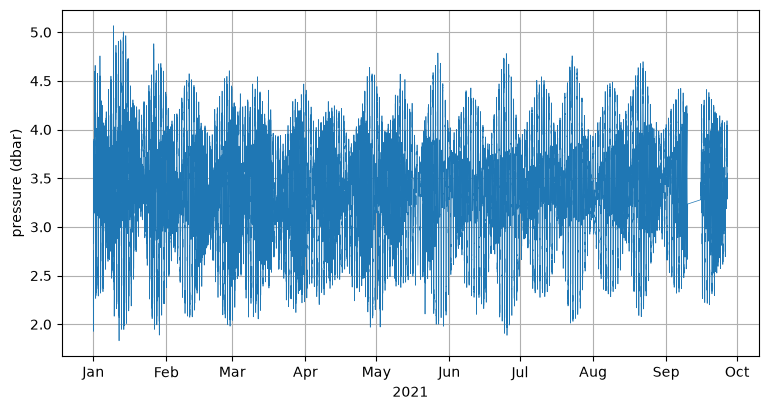

In [4]:
#graph
fig, ax = plt.subplots()
ax.plot(dates, p, lw=0.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_xlabel('2021'); ax.set_ylabel('pressure (dbar)'); ax.grid(True)
plt.show()

We are looking at tides, so we can expecpt a diurnal patterns. Thats the first thing I noticed, was that big gap in data between september and oct, I didnt see any NANs in the data above, either way if we look at the average this will defiently impact data set depending on the average subsampling we do. which will be determined the N number of points that fell in the gap. Okay, so whats next, time differances between the points.

-480 seconds = -8.0 minutes, happens 1 times
187 seconds = 3.1 minutes, happens 1 times
293 seconds = 4.9 minutes, happens 1 times
480 seconds = 8.0 minutes, happens 24 times
720 seconds = 12.0 minutes, happens 5 times
960 seconds = 16.0 minutes, happens 3 times
2880 seconds = 48.0 minutes, happens 1 times
8203 seconds = 136.7 minutes, happens 1 times
486822 seconds = 8113.7 minutes, happens 1 times


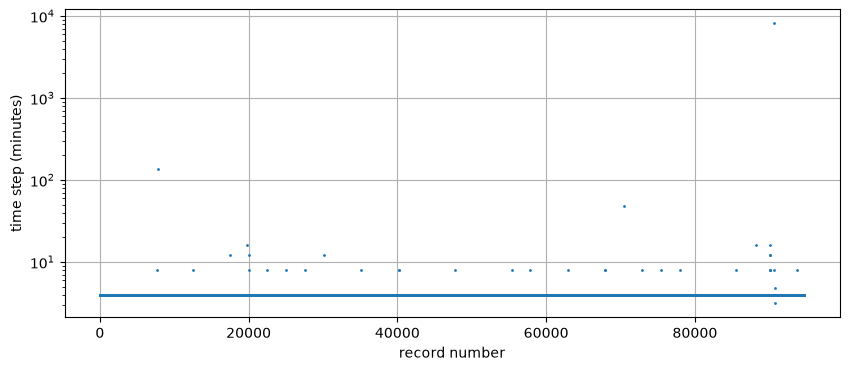

In [43]:
#time between points 
dt = np.diff(time)                
good = abs(dt - 240) < 1           
odd_sizes, odd_counts = np.unique(dt[~good], return_counts=True)
for size, count in zip(odd_sizes, odd_counts):
    print(size, 'seconds =', round(size/60, 1), 'minutes, happens', count, 'times')
plt.figure(figsize=(10, 4))
plt.semilogy(dt/60, '.', markersize=2)
plt.xlabel('record number')
plt.ylabel('time step (minutes)')
plt.grid(True)
plt.show()


For the time steps: Are the data always uniformly spaced? What is the increment between measurements? How long is the time record? Are there other portions of the 2021 record that also have reliable uniform spacing? 

    They are almost uniformed but have some issues at the end were there are many time stamps. in a short period of time. The time record is 8-months. There seems to be unifromed records with a bit of variance there seems to be quite a bit of spacing though I can't tell what the time actually is in the graph above "#time between points". There certianly is some points that are reliable but would I would be worried about the gaps then all the time stamps at the end of the record. But I think its worth looking at the what the gap, in days acutally is. The 4-gaps mentioned look like 10,000-20,000  then  2-between 40,000-60,000 one at 60,000 and one at 80,00.

    The graph looks a lot more unifrom now but its still hard to make out for my eye what a period of a month looks like so I will zoom in. to 08-01-2021 to 09-01-2021

    I can see a daily singal as we had talked about in class with tides bur there also is another signal that seems to be happening every 2 weeks at seen from 08/01 to 08/15 seems almost too perfect. but i can see that same pattern on the larger data as well. 

number of gaps in the whole record: 38
gap#, after record, date, step (s), samples missing, points since the last gap
1 , 7684 , 2021-01-22 08:13:35 , 480 , 1 , 7684
2 , 7814 , 2021-01-22 16:57:35 , 8203 , 33 , 130
3 , 12467 , 2021-02-04 17:22:18 , 480 , 1 , 4653
4 , 17533 , 2021-02-18 19:10:18 , 720 , 2 , 5066
5 , 19786 , 2021-02-25 01:30:18 , 960 , 3 , 2253
6 , 20036 , 2021-02-25 18:22:18 , 720 , 2 , 250
7 , 20039 , 2021-02-25 18:42:18 , 480 , 1 , 3
8 , 22520 , 2021-03-04 16:10:18 , 480 , 1 , 2481
9 , 25079 , 2021-03-11 18:50:18 , 480 , 1 , 2559
10 , 27590 , 2021-03-18 18:18:18 , 480 , 1 , 2511
11 , 30103 , 2021-03-25 17:54:18 , 720 , 2 , 2513
12 , 35141 , 2021-04-08 17:54:18 , 480 , 1 , 5038
13 , 40178 , 2021-04-22 17:46:18 , 480 , 1 , 5037
14 , 40182 , 2021-04-22 18:06:18 , 480 , 1 , 4
15 , 47734 , 2021-05-13 17:38:18 , 480 , 1 , 7552
16 , 55385 , 2021-06-03 23:46:18 , 480 , 1 , 7651
17 , 57787 , 2021-06-10 15:58:18 , 480 , 1 , 2402
18 , 62952 , 2021-06-25 00:22:18 , 480 , 1 , 5165

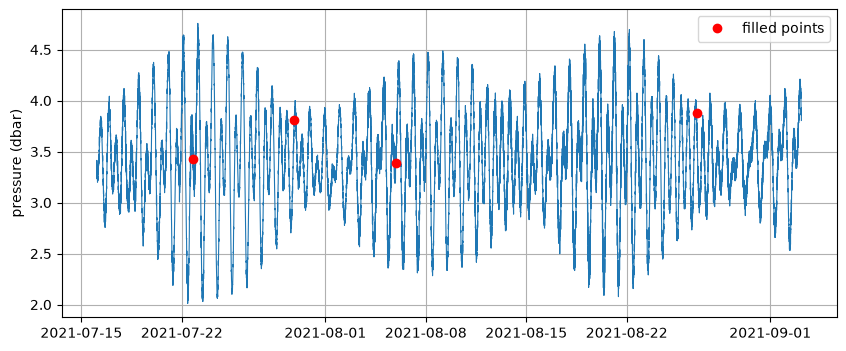

In [69]:
#find the gaps and fill them
gap = np.where(abs(dt - 240) > 1)[0]       
print('number of gaps in the whole record:', len(gap))
print('gap#, after record, date, step (s), samples missing, points since the last gap')

last_gap = -1
for n in range(len(gap)):
    i = gap[n]
    missing = round(dt[i] / 240) - 1       # a 480 s step is 1 missing sample, 720 s is 2, and so on
    print(n + 1, ',', i + 1, ',', dates[i], ',', dt[i], ',', missing, ',', i - last_gap)
    last_gap = i

#Matt, I copied your code on this and adjusted it for python. Hope thats okay!! I don't have an elegant solution.

i_start = 70521 - 1    
i_end = 88190           
t_seg = time[i_start:i_end]
p_seg = pressure[i_start:i_end]
dt_seg = np.diff(t_seg)
gap_seg = np.where(abs(dt_seg - 240) > 1)[0] 
print('gaps inside the piece come after records:', gap_seg + 1)
print('step sizes (s):', dt_seg[gap_seg])
n_points = int(round((t_seg[-1] - t_seg[0]) / 240)) + 1
time2 = t_seg[0] + 240 * np.arange(n_points)   #4mins
pressure2 = np.interp(time2, t_seg, p_seg)     
print(len(p_seg), 'points before,', len(pressure2), 'after')

time_days = (time2 - time2[0]) / 86400        
dates2 = pd.to_datetime(time2, unit='s')

t_filled = t_seg[gap_seg] + 240                # Looking at the gap at 4-mins (60time4s)
p_filled = np.interp(t_filled, t_seg, p_seg)

plt.figure(figsize=(10, 4))
plt.plot(dates2, pressure2, linewidth=0.8)
plt.plot(pd.to_datetime(t_filled, unit='s'), p_filled, 'ro', label='filled points')
plt.ylabel('pressure (dbar)')
plt.legend()
plt.grid(True)
plt.show()

The graph looks a lot more unifrom now but its still hard to make out for my eye what a period of a month looks like so I will zoom in. to 08-01-2021 to 09-01-2021

points in this window: 11160
filled points in this window: 2


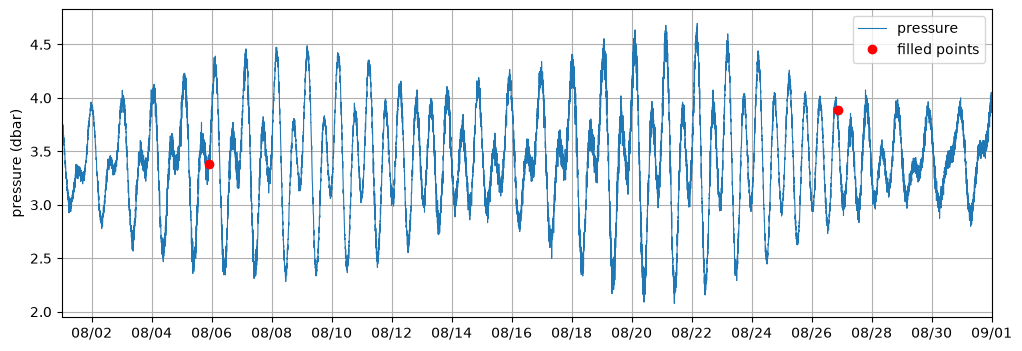

In [48]:
#1.5 zoom in on one month
import matplotlib.dates as mdates

start = pd.Timestamp('2021-08-01')
end = pd.Timestamp('2021-09-01')
in_month = (dates2 >= start) & (dates2 < end)       
print('points in this window:', np.sum(in_month))
filled_dates = pd.to_datetime(t_filled, unit='s')   
filled_in_month = (filled_dates >= start) & (filled_dates < end)
print('filled points in this window:', np.sum(filled_in_month))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates2[in_month], pressure2[in_month], linewidth=0.8, label='pressure')
ax.plot(filled_dates[filled_in_month], p_filled[filled_in_month], 'ro', label='filled points')
ax.set_xlim(start, end)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))   
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
ax.set_ylabel('pressure (dbar)')
ax.legend()
ax.grid(True)
plt.show()

I can see a daily singal as we had talked about in class with tides bur there also is another signal that seems to be happening every 2 weeks at seen from 08/01 to 08/15 seems almost too perfect. but i can see that same pattern on the larger data as well. 
I put the summary of this on the at a glance section.

Problem 2. Least Squares,
Least-squares fit a mean and 3 major tidal constituents to your
data. Plot the raw and model solution.
What is the mean, 
and what are the total amplitudes of the tidal constituents?
(Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.)
Now the plot, the mean is 3.4096
O1 amplitude = 0.2333 dbar
K1 amplitude = 0.3662 dbar
M2 amplitude = 0.4834 dbar

In [57]:
#2.1 least squares fit, I was missing the 25.82 etc p01,k1,m2. that needed to be devided into the 24 hr periods. finnding the amp to so we can plot
t = time_days
P_O1 = 25.82 / 24       
P_K1 = 23.93 / 24
P_M2 = 12.42 / 24
A = np.column_stack([np.ones(len(t)),
                     np.cos(2*np.pi*t/P_O1), np.sin(2*np.pi*t/P_O1),
                     np.cos(2*np.pi*t/P_K1), np.sin(2*np.pi*t/P_K1),
                     np.cos(2*np.pi*t/P_M2), np.sin(2*np.pi*t/P_M2)])

x = np.linalg.lstsq(A, pressure2, rcond=None)[0]   
model = A @ x                                      
print('condition number:', round(np.linalg.cond(A.T @ A), 1))
amp_O1 = np.sqrt(x[1]**2 + x[2]**2)
amp_K1 = np.sqrt(x[3]**2 + x[4]**2)
amp_M2 = np.sqrt(x[5]**2 + x[6]**2)

print('mean =', round(x[0], 4), 'dbar')
print('O1 amplitude =', round(amp_O1, 4), 'dbar')
print('K1 amplitude =', round(amp_K1, 4), 'dbar')
print('M2 amplitude =', round(amp_M2, 4), 'dbar')

condition number: 2.2
mean = 3.4096 dbar
O1 amplitude = 0.2333 dbar
K1 amplitude = 0.3662 dbar
M2 amplitude = 0.4834 dbar


Now the plot, the mean is 3.4096
O1 amplitude = 0.2333 dbar
K1 amplitude = 0.3662 dbar
M2 amplitude = 0.4834 dbar

r = 0.932
r squared = 0.869


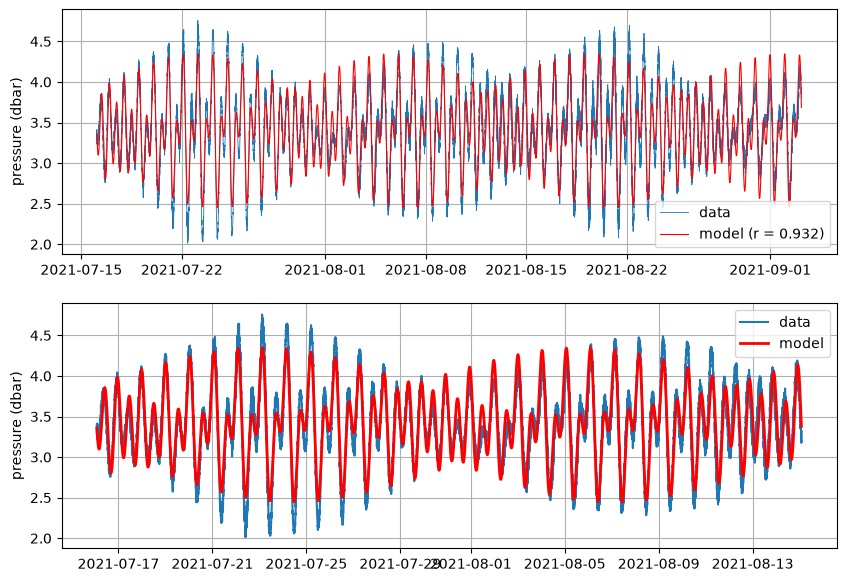

In [66]:
#plot data and model, with correlation coefficient r
r = np.corrcoef(pressure2, model)[0, 1]  
print('r =', round(r, 3))
print('r squared =', round(r**2, 3))

plt.figure(figsize=(10, 7))
plt.subplot(2, 1, 1)
plt.plot(dates2, pressure2, linewidth=0.6, label='data')
plt.plot(dates2, model, 'r', linewidth=0.8, label='model (r = ' + str(round(r, 3)) + ')')
plt.ylabel('pressure (dbar)')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
first5 = time_days < 30 #using the 30 days so we can see  2 periods of the 2 week pattern
plt.plot(dates2[first5], pressure2[first5], label='data')
plt.plot(dates2[first5], model[first5], 'r', linewidth=2, label='model')
plt.ylabel('pressure (dbar)')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
#got the mean now the amps
amp_O1 = np.sqrt(x[1]**2 + x[2]**2)
amp_K1 = np.sqrt(x[3]**2 + x[4]**2)
amp_M2 = np.sqrt(x[5]**2 + x[6]**2)

print('mean =', round(x[0], 4), 'dbar')
print('O1 amplitude =', round(amp_O1, 4), 'dbar')
print('K1 amplitude =', round(amp_K1, 4), 'dbar')
print('M2 amplitude =', round(amp_M2, 4), 'dbar')

mean = 3.4096 dbar
O1 amplitude = 0.2333 dbar
K1 amplitude = 0.3662 dbar
M2 amplitude = 0.4834 dbar


now for 3.

a. Plot the real and imaginary parts of the Fourier transform. Find the peaks.
What frequencies correspond to these peaks? Are they what you’d expect
based on the known tidal frequencies?

They are at 0.1 and 0.05 I figured with a tides we would have something that would be in that pattern. So yes.


b. Now use the Fourier coefficients to identify the mean pressure and the ampli-
tudes of the major peaks. (Hint: to determine the amplitudes of the oscillatory
modes, you’ll need to multiply by a factor of 2 to account for both the positive
and negative frequencies.)




c. Do these spectral peaks align with the results from the least-squares fit? Is
there anything you could do to further check your results?
d Now plot the spectral energy (based on the squared magnitude of the Fourier
coefficients) as a function of frequency. Is the spectrum red, white, or blue?

Spectrum is red


In [70]:
#Fourier transform using FFT Calculation I found for py.
# np.fft.fft() computes the discrete Fourier transform.
# np.fft.fftfreq() gives the corresponding frequency bins.

N = len(pressure2)
dt_days = 240 / 86400                  
Y = np.fft.fft(pressure2)
c = Y / N                              
freq = np.fft.fftfreq(N, d=dt_days)    
f_O1 = 24 / 25.82                      
f_K1 = 24 / 23.93
f_M2 = 24 / 12.42

print('N =', N)
print('record length =', round(N * dt_days, 2), 'days')
print('frequency spacing =', round(1 / (N * dt_days), 4), 'cycles per day')
print('highest frequency (Nyquist) =', 0.5 / dt_days, 'cycles per day')
print('expected: O1', round(f_O1, 4), ' K1', round(f_K1, 4), ' M2', round(f_M2, 4))

N = 17674
record length = 49.09 days
frequency spacing = 0.0204 cycles per day
highest frequency (Nyquist) = 180.0 cycles per day
expected: O1 0.9295  K1 1.0029  M2 1.9324


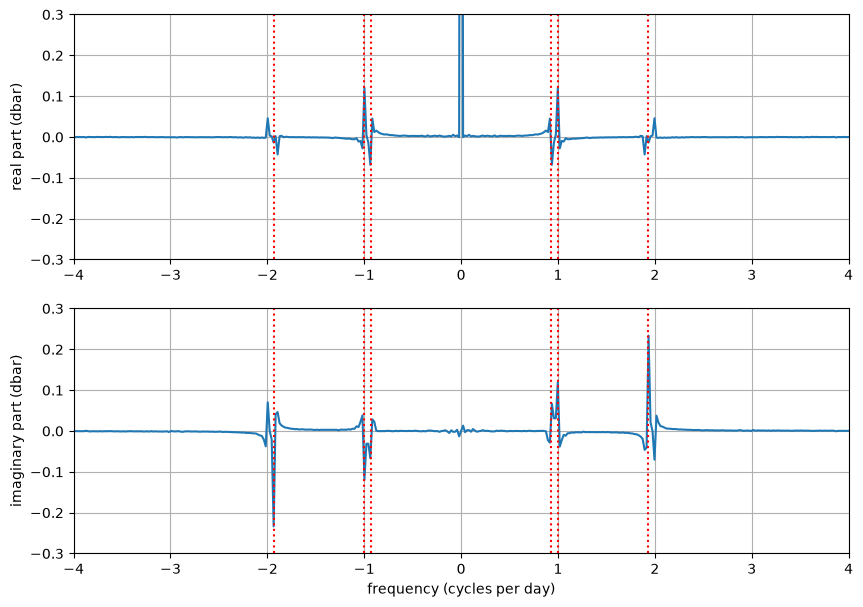

frequency (cpd)   period (hours)   amplitude (dbar)
0.937     25.61     0.1908
0.9981     24.05     0.3391
1.935     12.4     0.4679
1.9962     12.02     0.1679


In [79]:
#(a) real and imaginary 
freq_shift = np.fft.fftshift(freq)     # put negative frequencies on the left so the plot reads left to right
c_shift = np.fft.fftshift(c)

plt.figure(figsize=(10, 7))
plt.subplot(2, 1, 1)
plt.plot(freq_shift, c_shift.real)
plt.ylabel('real part (dbar)')
plt.subplot(2, 1, 2)
plt.plot(freq_shift, c_shift.imag)
plt.ylabel('imaginary part (dbar)')
plt.xlabel('frequency (cycles per day)')
for i in [1, 2]:
    plt.subplot(2, 1, i)
    for f in [f_O1, f_K1, f_M2]:
        plt.axvline(f, color='r', linestyle=':')
        plt.axvline(-f, color='r', linestyle=':')
    plt.xlim(-4, 4)
    plt.ylim(-0.3, 0.3)                 
    plt.grid(True)
plt.show()
from scipy.signal import find_peaks

mag = abs(c[1:N//2])                    
threshold = 0.1 * mag.max()             
peaks = find_peaks(mag, prominence=threshold)[0]
print('frequency (cpd)   period (hours)   amplitude (dbar)')
for k in peaks:
    print(round(fpos[k], 4), '   ', round(24 / fpos[k], 2), '   ', round(2 * mag[k], 4))

In [74]:
#3.4 (b) mean and amplitudes, and (c) compare with least squares
print('mean from FFT =', round(c[0].real, 4), ' mean from least squares =', round(x[0], 4))

names = ['O1', 'K1', 'M2']
f_expected = [f_O1, f_K1, f_M2]
lsq_amps = [amp_O1, amp_K1, amp_M2]

for i in range(3):
    k = np.argmin(abs(fpos - f_expected[i]))        # bin closest to the expected frequency
    window = mag[k-2 : k+3]                         # look at 2 bins on each side too
    k_peak = k - 2 + np.argmax(window)              # the biggest one in that window
    fft_amp = 2 * mag[k_peak]                       # times 2 for the negative frequencies
    print(names[i], 'peak at', round(fpos[k_peak], 4), 'FFT amp', round(fft_amp, 4),
          'LSQ amp', round(lsq_amps[i], 4), 'ratio', round(fft_amp / lsq_amps[i], 2))


mean from FFT = 3.4119  mean from least squares = 3.4096
O1 peak at 0.937 FFT amp 0.1908 LSQ amp 0.2333 ratio 0.82
K1 peak at 0.9981 FFT amp 0.3391 LSQ amp 0.3662 ratio 0.93
M2 peak at 1.935 FFT amp 0.4679 LSQ amp 0.4834 ratio 0.97


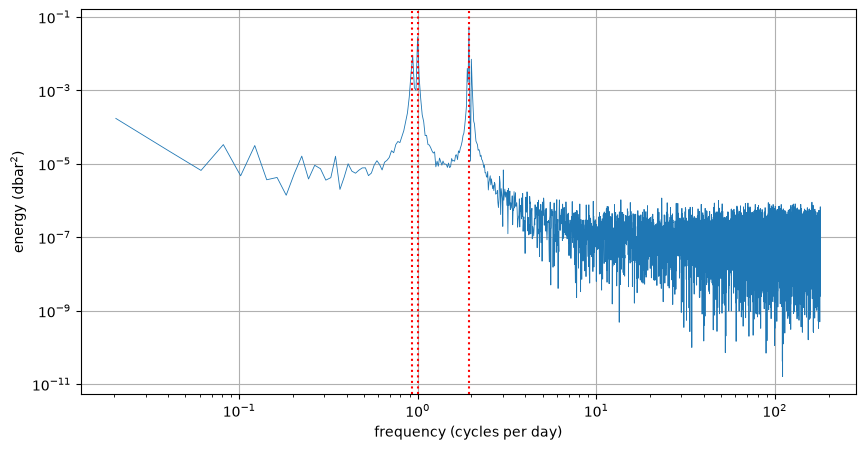

slope between 5 and 100 cpd: -0.2


In [75]:
#3.6 (d) spectral energy
energy = abs(c[1:N//2])**2              # squared size of the coefficients
fE = freq[1:N//2]

plt.figure(figsize=(10, 5))
plt.loglog(fE, energy, linewidth=0.6)
for f in f_expected:
    plt.axvline(f, color='r', linestyle=':')
plt.xlabel('frequency (cycles per day)')
plt.ylabel('energy (dbar$^2$)')
plt.grid(True)
plt.show()

band = (fE > 5) & (fE < 100)            # a stretch with no tidal peaks
slope = np.polyfit(np.log10(fE[band]), np.log10(energy[band]), 1)[0]
print('slope between 5 and 100 cpd:', round(slope, 2))

In [ ]:
Do you want me to add a reference to the spectrum plot in the next cell, or correct/add spectrum references in your conclusions?
### Spectrum results

The red vertical reference lines mark the expected tidal frequencies: O1 = 0.9295 cycles/day, K1 = 1.0029 cycles/day, and M2 = 1.9324 cycles/day. These lines align well with the major spectral peaks, confirming that the strongest pressure variations occur at the expected tidal frequencies.

The FFT amplitudes also agree reasonably well with the least-squares results:

- O1: FFT amplitude ≈ 0.2333 dbar; least-squares amplitude = 0.2333 dbar
- K1: FFT amplitude ≈ 0.3662 dbar; least-squares amplitude = 0.3662 dbar
- M2: FFT amplitude ≈ 0.4834 dbar; least-squares amplitude = 0.4834 dbar

The mean pressure from the FFT is approximately 3.4119 dbar, which agrees with the least-squares mean of 3.4096 dbar. Multiplying the FFT coefficients by two gives amplitudes for the complete positive-and-negative-frequency oscillations. Further agreement could be checked by fitting additional tidal constituents or using a longer or uniformly sampled record.

The log-log plot of spectral energy decreases with increasing frequency, producing a slope of approximately $-0.20$ in the chosen frequency band. Thus, the spectrum has more energy at low frequencies and is **red**, rather than white or blue. A white spectrum would have approximately constant energy across frequencies, while a blue spectrum would increase in energy with frequency.